In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


#library jo dataset load krane mein help kregi
from datasets import load_dataset

In [ ]:
emotion_dataset=load_dataset('dair-ai/emotion')
emotion_dataset

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

In [ ]:
train_text=emotion_dataset['train']['text']
train_label=emotion_dataset['train']['label']

test_text=emotion_dataset['test']['text']
test_label=emotion_dataset['test']['label']

In [ ]:
label_names=emotion_dataset['train'].features['label'].names

In [ ]:
df_train=pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i] for i in train_label]
    }
)

df_test=pd.DataFrame(
    {
        'text':test_text,
        'label':[label_names[i] for i in test_label]
    }
)

In [ ]:
df_train.head(5)

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df_train.isnull().sum()

,0
text,0
label,0


### Exploratory Data Analysis(EDA)


<Axes: xlabel='label', ylabel='count'>

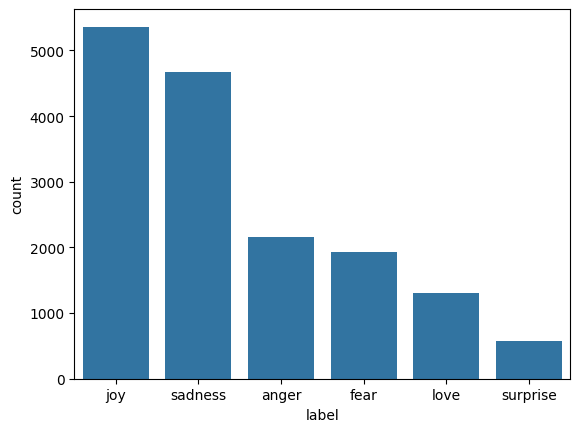

In [ ]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)

### Data Preprocessing - Using NLP

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=10000

tokenizer=Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence=tokenizer.texts_to_sequences(df_train['text'])
train_sequence

test_sequence=tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence=pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')

padded_test_sequence=pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')
padded_train_sequence

train_labels=np.array(train_label)
test_labels  = np.array(test_label)

num_classes=len(np.unique(train_labels))
num_classes

print(f"Vocabulary Size:{len(tokenizer.word_index)}")
print(f"Max Sequence Length:{padded_train_sequence.shape[1]}")

Vocabulary Size:15213
Max Sequence Length:50


### Shared Traing Utilites

compute balance class weight to handle dataset skew and setup early stopping

In [ ]:
from sklearn.utils import class_weight
class_weights=class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dict=dict(enumerate(class_weights))

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping=EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True

)

## Phase 1 - Plain Foundation Model
Train plain(non-bidirectional) Simple RNN , Standard LSTM , and Standard GRU models

Model 1- Simple RNN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Embedding, Dense , Dropout,LSTM,GRU

rnn_model = Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    SimpleRNN(units=128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(num_classes,activation='softmax') #Output Layer

])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]

)

rnn_loss,rnn_accuracy=rnn_model.evaluate(padded_test_sequence,test_labels)
print(f"RNN Loss:{rnn_loss}")
print(f"RNN Accuracy:{rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 35s 65ms/step - accuracy: 0.1643 - loss: 2.0453 - val_accuracy: 0.1660 - val_loss: 1.7787
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 56ms/step - accuracy: 0.1523 - loss: 1.8892 - val_accuracy: 0.2555 - val_loss: 1.7356
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 49ms/step - accuracy: 0.1340 - loss: 1.8294 - val_accuracy: 0.2905 - val_loss: 1.7607
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 50ms/step - accuracy: 0.1377 - loss: 1.8070 - val_accuracy: 0.2905 - val_loss: 1.7459
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.1444 - loss: 1.8015 - val_accuracy: 0.0795 - val_loss: 1.7775
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2555 - loss: 1.7356
RNN Loss:1.7355930805206299
RNN Accuracy:0.2554999887943268


Model 2 - Standard LSTM
plain stcked Long-short- Term Memory network

In [ ]:
lstm_model = Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    LSTM(units=128,return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(num_classes,activation='softmax') #Output Layer

])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]

)

lstm_loss,lstm_accuracy=lstm_model.evaluate(padded_test_sequence,test_labels)
print(f"LSTM Loss:{lstm_loss}")
print(f"LSTM Accuracy:{lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 69s 132ms/step - accuracy: 0.1664 - loss: 1.7947 - val_accuracy: 0.0330 - val_loss: 1.8226
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 131ms/step - accuracy: 0.1406 - loss: 1.7939 - val_accuracy: 0.0335 - val_loss: 1.7927
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 65s 130ms/step - accuracy: 0.1429 - loss: 1.7900 - val_accuracy: 0.1215 - val_loss: 1.7982
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0330 - loss: 1.8226
LSTM Loss:1.8225692510604858
LSTM Accuracy:0.032999999821186066


In [ ]:
gru_model = Sequential([
    Embedding(input_dim=max_words,output_dim=128,input_length=50),
    GRU(units=128,return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(num_classes,activation='softmax') #Output Layer

])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]

)

gru_loss,gru_accuracy=gru_model.evaluate(padded_test_sequence,test_labels)
print(f"GRU Loss:{gru_loss}")
print(f"GRU Accuracy:{gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 60s 113ms/step - accuracy: 0.1594 - loss: 1.7963 - val_accuracy: 0.1125 - val_loss: 1.7956
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - accuracy: 0.1549 - loss: 1.7947 - val_accuracy: 0.0360 - val_loss: 1.8174
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 57s 114ms/step - accuracy: 0.1657 - loss: 1.7943 - val_accuracy: 0.1110 - val_loss: 1.8080
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.1125 - loss: 1.7956
GRU Loss:1.7955678701400757
GRU Accuracy:0.11249999701976776


In [ ]:
result_df=pd.DataFrame({
    'Model':['RNN','LSTM','GRU'],
    'Test Loss':[rnn_loss,lstm_loss,gru_loss],
    'Accuracy':[rnn_accuracy,lstm_accuracy,gru_accuracy]
}).sort_values(by='Accuracy',ascending=False)
result_df

,Model,Test Loss,Accuracy
0,RNN,1.735593,0.2555
2,GRU,1.795568,0.1125
1,LSTM,1.822569,0.0330


## Phase 2 - Advanced Bidirectional GRU

Enhance GRU with Bidirectional layers , 300D embeddings , and 0.5 dropout regularization

In [ ]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim=max_words,output_dim=300,input_length=50),
    Bidirectional(GRU(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes,activation='softmax') #Output Layer
])

BiGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
BiGRU.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Train & Evaluate Advanced Bidirectional GRU

In [ ]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence,test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]

)

BiGRU_loss,BiGRU_accuracy=BiGRU.evaluate(padded_test_sequence,test_labels)
print(f"BiGRU Loss:{BiGRU_loss}")
print(f"BiGRU Accuracy:{BiGRU_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 166s 314ms/step - accuracy: 0.5787 - loss: 1.0211 - val_accuracy: 0.8920 - val_loss: 0.3474
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 159s 318ms/step - accuracy: 0.9120 - loss: 0.2507 - val_accuracy: 0.9110 - val_loss: 0.2665
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 153s 306ms/step - accuracy: 0.9440 - loss: 0.1504 - val_accuracy: 0.9135 - val_loss: 0.2186
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 153s 307ms/step - accuracy: 0.9591 - loss: 0.1083 - val_accuracy: 0.9180 - val_loss: 0.2860
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 155s 310ms/step - accuracy: 0.9696 - loss: 0.0843 - val_accuracy: 0.9215 - val_loss: 0.2474
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 153s 307ms/step - accuracy: 0.9725 - loss: 0.0784 - val_accuracy: 0.9230 - val_loss: 0.2805
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.9135 - loss: 0.2186
BiGRU Loss:0.21860802173614502
BiGRU Accuracy:0.9135000109672546


Final Model Confusion Matrices

63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 124ms/step


<Axes: >

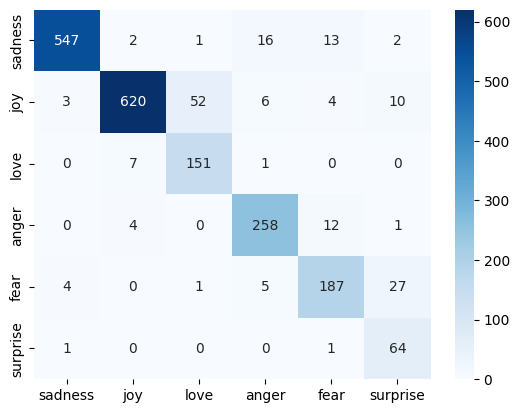

In [ ]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions=np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label,BiGRU_predictions),annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)

## Final Prediction

In [ ]:
sample_texts=[
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences=tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences=pad_sequences(sample_sequences,maxlen=50,padding='post',truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences),axis=1)

for i in range(len(sample_texts)):
  print(f"{sample_texts[i]}\nPredicted Emotion:{label_names[sample_predictions[i]]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
I can't believe how happy I am right now, this is amazing!
Predicted Emotion:surprise
I feel so alone and hopeless today.
Predicted Emotion:sadness
I am furious that they cancelled the trip at the last minute.
Predicted Emotion:anger
I feel terrified when walking down dark alleyways alone.
Predicted Emotion:fear
I was shocked and completely surprised by the unexpected gift!
Predicted Emotion:surprise


Save The Model ANd Tokenizer

In [37]:
import os
import pickle

model_dir='Artifacts' #this is the folder inside which all exported file will come
os.makedirs(model_dir,exist_ok=True)

#Save our Bigru Model
BiGRU.save(os.path.join(model_dir,'BiGRU_Model.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)